# Student Performance Analysis & Machine Learning

Originally submitted as **FIT1043 Introduction to Data Science — Data Science Assignment 1** (Monash University, Semester 2 2025).

Author: Surya Muni Peragas


**A1: DATA WRANGLING**

Question 1

In [1]:
import pandas as pd 
df = pd.read_csv('data/Student_List_A2.csv')
#Gets a list of all column names from the df data frame.
column_names = df.columns.tolist()
print(column_names)

['StudentID', 'Age', 'StudyTimeWeekly', 'Absences', 'ParentalSupport', 'GPA', 'GradeClass']


Explanation:
The code imports the pandas library and reads the CSV file. It then extracts the column names and prints it as a list.

Question 2

In [2]:
#Using a dictionary to map old values with new values.
df['GradeClass'] = df['GradeClass'].replace({0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'F'})
df.head()

,StudentID,Age,StudyTimeWeekly,Absences,ParentalSupport,GPA,GradeClass
0,1002,18,15.408756,0,1,3.042915,B
1,1003,15,4.210570,26,2,0.112602,F
2,1004,17,10.028829,14,3,2.054218,D
3,1005,17,4.672495,17,3,1.288061,F
4,1006,18,8.191219,0,1,3.084184,B


Explanation:
We use the replace method to update the values in the 'GradeClass' column. The dictionary was created to map the corresponding letter grades to 
the numerical value of 0 to 4. 

Question 3 

In [3]:
print("Missing values before imputation:")
missing_before = df.isnull().sum()
print(missing_before)

columns_with_missing = missing_before[missing_before > 0].index.tolist()

for col in columns_with_missing:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

print("\n")
print("Missing values after imputation:")
missing_after = df.isnull().sum()
print(missing_after)


Missing values before imputation:
StudentID           0
Age                 0
StudyTimeWeekly    21
Absences            0
ParentalSupport     0
GPA                 0
GradeClass          0
dtype: int64


Missing values after imputation:
StudentID          0
Age                0
StudyTimeWeekly    0
Absences           0
ParentalSupport    0
GPA                0
GradeClass         0
dtype: int64


Explanation:
First, df.isnull().sum() is used to count the number of missing (or null) values in each column. The output reveals that the 'StudyTimeWeekly' column contains 21 missing values. We replace the missing values with the median of the 'StudyTimeWeekly' column. The median is chosen because it is less sensitive to outliers than the mean. The code iterates through each column that has missing values, calculates its median using df[col].median(), and then fills the null entries with this median value using .fillna().

Question 4

In [4]:
df['Absences'].describe()

count    2100.000000
mean       14.709048
std        11.153253
min      -122.000000
25%         7.000000
50%        15.000000
75%        22.000000
max       320.000000
Name: Absences, dtype: float64

In [5]:
df['Absences'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 2100 entries, 0 to 2099
Series name: Absences
Non-Null Count  Dtype
--------------  -----
2100 non-null   int64
dtypes: int64(1)
memory usage: 16.5 KB


Explanation:
To investigate the data quality of the 'Absences' column, we first use the .describe() method. This function generates descriptive statistics, including the count, mean, standard deviation, minimum, and maximum values. The output immediately highlights a problem where the minimum value for absences is -122, and the maximum is 320. Negative absences are logically impossible, and an unusually high number of absences might be an error or an outlier. The .info() method is used to confirm the data type is numerical (int64) and that there are no missing values.

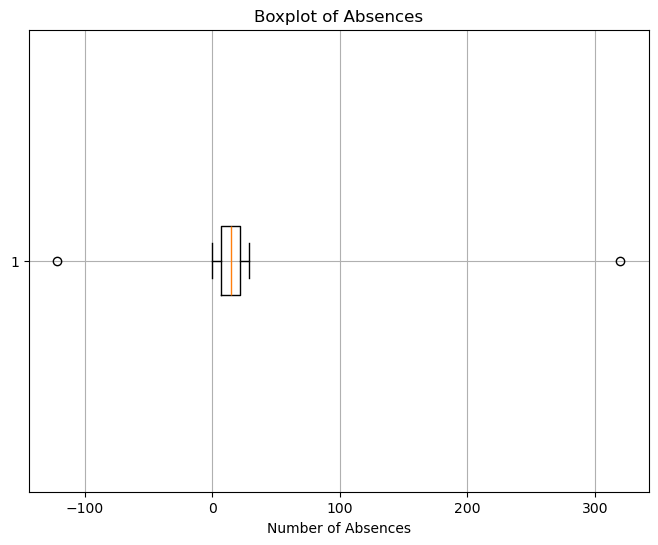

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.boxplot(df['Absences'], vert=False)
plt.title('Boxplot of Absences')
plt.xlabel('Number of Absences')
plt.grid(True)
plt.show()

In [7]:
problematic_rows = df[(df['Absences'] > 30) | (df['Absences'] < 0)]
problematic_rows

,StudentID,Age,StudyTimeWeekly,Absences,ParentalSupport,GPA,GradeClass
112,1114,16,16.849282,320,1,1.919956,F
1001,2003,15,0.806505,-122,3,3.201710,B


Explanation:
A boxplot is generated to visualize the distribution of the 'Absences' data and identify outliers. The plot clearly shows points far below zero and above a reasonable upper limit, confirming the presence of problematic data. To isolate these rows, this boolean filter is created: (df['Absences'] > 30) | (df['Absences'] < 0). This condition selects all rows where the number of absences is either negative or exceeds 30. 

In [8]:
df = df[(df['Absences'] <= 30) & (df['Absences'] >= 0)]
df['Absences'].describe()

count    2098.000000
mean       14.628694
std         8.434995
min         0.000000
25%         7.000000
50%        15.000000
75%        22.000000
max        29.000000
Name: Absences, dtype: float64

Explanation:
This code cleans the dataset by removing the problematic rows. It filters the data frame to keep only the rows where 'Absences' are between 0 and 30, inclusive. The describe method is used again to confirm that the minimum and maximum values are now in a reasonable range. 

Explanation on why such a problem might realistically occur in student dataset:
This can happen due to data entry errors, system glitches while transfering data, or incorrect calculations in the source system.

Question 5

In [9]:
def get_expected_grade(gpa):
    if gpa >= 3.5:
        return 'A'
    elif 3.0 <= gpa < 3.5:
        return 'B'
    elif 2.5 <= gpa < 3.0:
        return 'C'
    elif 2.0 <= gpa < 2.5:
        return 'D'
    else:
        return 'F'

In [10]:
df['ExpectedGrade'] = df['GPA'].apply(get_expected_grade)
inconsistencies = df[df['GradeClass'] != df['ExpectedGrade']]
count_incon = len(inconsistencies)
example_student_ids = inconsistencies['StudentID'].head(10).tolist()
print(f"Count of inconsistencies: {count_incon}")
print(f"Example StudentID's of inconsistencies: {example_student_ids}")

Count of inconsistencies: 100
Example StudentID's of inconsistencies: [3182, 3183, 3189, 3193, 3195, 3199, 3202, 3206, 3208, 3210]


Explanation: The function get_expected_grade is created to determine the correct letter grade based on a given GPA. This function is then applied to the 'GPA' column of the data frame using the .apply() method, creating a new column called 'ExpectedGrade'. The code then compared 'GradeClass' column and 'ExpectedGrade' column to see if there are any rows that do not match values. If the values don't match it is stored in inconsistencies data frame. Then, we print the number of inconsistencies and display some StudentIDs of inconsistent values.

In [11]:
df['GradeClass'] = df['ExpectedGrade']  # Overwrite 'GradeClass' column with values derived from the GPA
df.drop('ExpectedGrade', axis=1, inplace=True) 

# Re-audit to confirm zero inconsistencies
df['ExpectedGrade'] = df['GPA'].apply(get_expected_grade)
inconsistencies_after = df[df['GradeClass'] != df['ExpectedGrade']]
print(f"Count of inconsistencies after resolution: {len(inconsistencies_after)}")  
df.drop('ExpectedGrade', axis=1, inplace=True)

Count of inconsistencies after resolution: 0


Explanation:
I have decided to trust the GPA column because they are a more accurate representation of a person's grades. Converting a person's letter grade to GPA can only have a range as the value whereas converting a GPA to letter grade will always be a single value which is a letter. The code overwrites the 'GradeClass' column with the values from the 'ExpectedGrade' column. The temporary 'ExpectedGrade' column is then removed. A re-audit is performed by recreating the 'ExpectedGrade' column and checking for inconsistencies again to confirm that the number of inconsistencies are now zero.

**A2: Data Exploration and Visualization**

Question 1

In [12]:
#Count the occurences of unique values and convert counts to proportions
grades_percentages = df['GradeClass'].value_counts(normalize=True) * 100
print(grades_percentages)

GradeClass
F    53.622498
D    17.588179
C    16.158246
B     9.723546
A     2.907531
Name: proportion, dtype: float64


Question 2

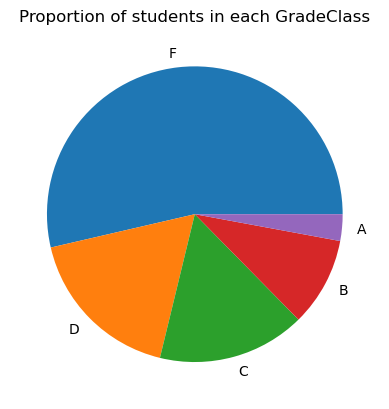

In [13]:
plt.pie(grades_percentages, labels=grades_percentages.index)
plt.title('Proportion of students in each GradeClass')
plt.show()

Explanation: The pie chart provides a basic visual of proportion of students in each grade class. According to the pie chart, we can see that the majority of students have achieved 'F' grade whereas there are only a few people who managed to get 'A' grade. The current pie chart lacks percentage calculation of each slices. 

Question 3

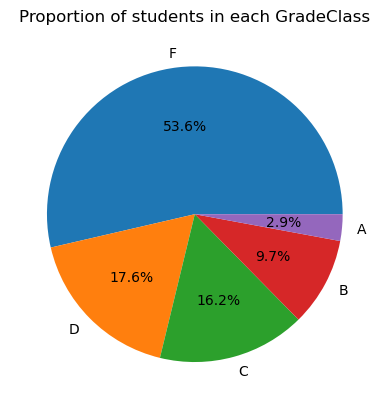

In [14]:
plt.pie(grades_percentages, labels=grades_percentages.index, autopct='%1.1f%%')
plt.title('Proportion of students in each GradeClass')
plt.show()

Explanation:
The percentages shown on the pie chart slices match the values calculated in question 1. Any slight variations would result from the autopct formatting's rounding.

Question 4

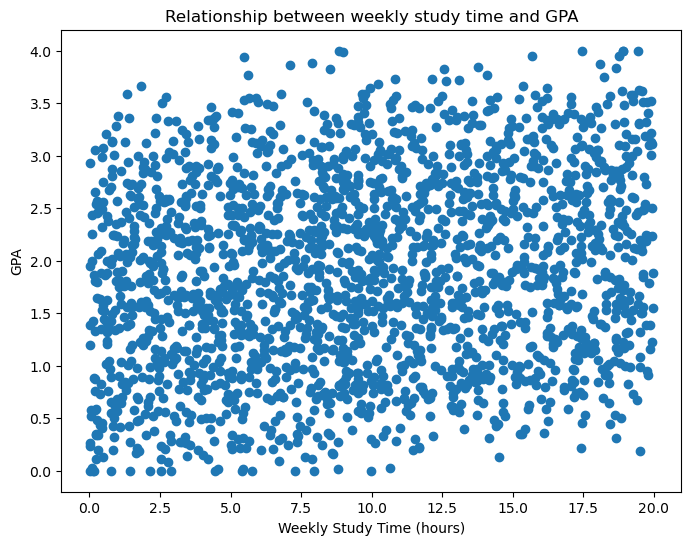

Correlation: 0.1790583119758245


In [15]:
# Create a figure for the scatter plot
plt.figure(figsize=(8,6))
# Generating a scatter plot to visualize the relationship between 'StudyTimeWeekly' and 'GPA'.
plt.scatter(df['StudyTimeWeekly'], df['GPA'])

# Set up the title, x-axis and y-axis label.
plt.title('Relationship between weekly study time and GPA')
plt.xlabel('Weekly Study Time (hours)')
plt.ylabel('GPA')

plt.show()

# Calculates the Pearson correlation coefficient between 'StudyTimeWeekly' and 'GPA'
correlation = df['StudyTimeWeekly'].corr(df['GPA'])
print("Correlation:", correlation)

Explanation: The Pearson correlation is approximately 0.179. This means that the strength of association between weekly study time and GPA is weak. Therefore, there is a very slight tendency for GPA to increase as weekly study time increases.

Question 5

In [16]:
# Calculates the Pearson correlation coefficient between 'Absences' and 'GPA'
corr_absences = df['Absences'].corr(df['GPA'])
print(corr_absences)

-0.9197788569386008


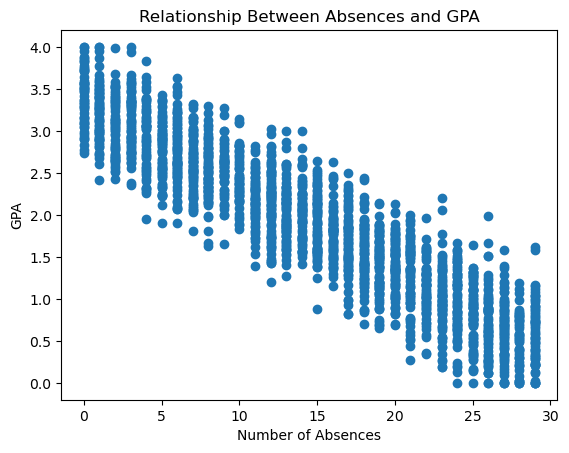

In [17]:
# Generating a scatter plot to visualize the relationship between 'Absences' and 'GPA'.
plt.scatter(df['Absences'], df['GPA'])
plt.title('Relationship Between Absences and GPA')
plt.xlabel('Number of Absences')
plt.ylabel('GPA')
plt.show()

Explanation: Here, the Pearson correlation between absences and GPA is approximately -0.92. This means that the strength of association between weekly study time and GPA is very strong. We can even see in the plot that as the number of absences increases, the GPA tends to descrease significantly. In terms of student behaviour, students who miss classes suffer from missed instructions, struggle to keep up with the materials and miss feedbacks from the teacher. Therefore, consistent attendance is important for academic success.

Question 6

Correlation alone is not sufficient to conclude causation in this dataset. For example, the negative correlation between absences and GPA doesn't necessarily mean that absences can cause lower grades. There might be factors like students with health issues might miss more classes and also perform poorly. There might also be students struggling academically who might avoid classes. Moreover, students who understand the material better might enjoy studying more. 

Additional data to strengthen argument:
- Adding external variables like motivation, prior knowledge and health condition

Question 7

In [18]:
grade_stats = df.groupby('GradeClass').agg({
    'GPA': ['mean', 'median', 'std', lambda x: x.quantile(0.75) - x.quantile(0.25)],
    'Absences': ['mean', 'median', 'std', lambda x: x.quantile(0.75) - x.quantile(0.25)]
})

grade_stats

GPA                                  Absences         \
                mean    median       std <lambda_0>       mean median   
GradeClass                                                              
A           3.681490  3.618273  0.163589   0.275281   1.475410    1.0   
B           3.227285  3.219432  0.143109   0.242832   3.308824    3.0   
C           2.732964  2.723828  0.145818   0.250655   6.433628    6.0   
D           2.249837  2.240924  0.137388   0.230745  11.140921   11.0   
F           1.181513  1.234141  0.513394   0.788061  21.008000   21.0   

                                 
                 std <lambda_0>  
GradeClass                       
A           1.659383        3.0  
B           2.500782        4.0  
C           3.562318        5.0  
D           3.783787        6.0  
F           5.033246        8.0

Question 8

In [19]:
# Reset the index to make the 'GradeClass' column from an index to a regular column
grade_stats = grade_stats.reset_index()

# Defining a new list of column names that are single-level
new_column_names = ['GradeClass',
                    'GPA_mean', 'GPA_median', 'GPA_std', 'GPA_iqr', 
                    'Absences_mean', 'Absences_median', 'Absences_std', 'Absences_iqr']

# Applying the new column names to the data frame.
grade_stats.columns = new_column_names
grade_stats

,GradeClass,GPA_mean,GPA_median,GPA_std,GPA_iqr,Absences_mean,Absences_median,Absences_std,Absences_iqr
0,A,3.681490,3.618273,0.163589,0.275281,1.475410,1.0,1.659383,3.0
1,B,3.227285,3.219432,0.143109,0.242832,3.308824,3.0,2.500782,4.0
2,C,2.732964,2.723828,0.145818,0.250655,6.433628,6.0,3.562318,5.0
3,D,2.249837,2.240924,0.137388,0.230745,11.140921,11.0,3.783787,6.0
4,F,1.181513,1.234141,0.513394,0.788061,21.008000,21.0,5.033246,8.0


**A3: Supervised Learning**

Question 1

Supervised machine learning involves training a model on labeled data to predict outcomes for new data. Here, 'GradeClass' is the label, and features like study time weekly, absences and parental support predict it. Training is fitting the model to a subset of data to learn patterns. Testing is evaluating the model on unseen data to assess generalization. One risk of not holding out a test set is overfitting where the model performs well on training data but poorly on new data, giving a false sense of accuracy.

Question 2

In [20]:
features = df.drop(['GradeClass', 'StudentID', 'GPA'], axis=1)  # Features
label = df['GradeClass']  # Label

features

,Age,StudyTimeWeekly,Absences,ParentalSupport
0,18,15.408756,0,1
1,15,4.210570,26,2
2,17,10.028829,14,3
3,17,4.672495,17,3
4,18,8.191219,0,1
...,...,...,...,...
2095,16,1.445434,20,3
2096,18,10.680555,2,4
2097,16,6.805500,20,2
2098,16,12.416653,17,2


Feature Selection Justification:

Included features:
- Age: Older or younger students will have differences in study habbits and consistencies. 
- Study time weekly: People who study longer time are expected to get better results which makes it a strong predictor.
- Absences: It is highly correlated with GPA making it a great predictor aswell
- Parental Support: Family support often improves a students overall motivation which can cause an increase in their academic performance.

Excluded  features:
- StudentID: Since this is an identifier, it doesn't carry any useful information
- GPA: This is used directly to get the GradeClass. Including it would make the prediction insignificant.
- Grade Class: This is the label itself so it cannot be included in the features.

Question 3

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
# test_size=0.3 means 30% of the data will be used for testing.
# stratify=label ensures the class distribution is the same in both train and test sets.
X_train, X_test, y_train, y_test = train_test_split(features, label, test_size=0.3, stratify = label, random_state=42)
print("Train samples:", len(X_train), "Test samples:", len(X_test))

Train samples: 1468 Test samples: 630


Justification for 70/30 split with small dataset:

With a very small dataset, a 70/30 split might not be ideal because:
1. There is less data for training the model
2. The test set might be too small to provide accurate estimation

**A4: Classification**

Question 1

Normalisation makes sure that features are on the same scale. This prevents features having larger ranges which can be bad for distance-based algorithms like support vector machine. For example, Age (range 15-18) vs Absences (0-30): Without scaling, Absences would dominate the distance calculation due to its larger variance, leading to biased model decisions.

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
# List of numerical columns that will be scaled
numerical_cols = ['Age', 'StudyTimeWeekly', 'Absences', 'ParentalSupport']
sc = StandardScaler()
X_train[numerical_cols] = sc.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = sc.transform(X_test[numerical_cols])

print("Scaled columns:")
numerical_cols

Scaled columns:


['Age', 'StudyTimeWeekly', 'Absences', 'ParentalSupport']

Question 2

Description of SVM:
SVM is a supervised classification algorithm that finds the optimal hyperplane to separate classes with the maximum margin. It uses support vectors (data points closest to the hyperplane) to define the boundary and can handle non-linear data via kernels.

Description of kernel:
The kernel is a function that transforms data into a higher-dimensional space where linear separation becomes possible. Common kernels include linear, polynomial, and RBF (radial basis function), allowing SVM to handle complex patterns without explicit transformation.

In [25]:
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(features, label, test_size=0.15, stratify = label, random_state=42)
print("Train samples:", len(X_train_2), "Test samples:", len(X_test_2))

Train samples: 1783 Test samples: 315


Explanation:
I have split my data for training and testing where 85% of the data is used for training whereas 15% of the data is used for testing. The goal here is to give my models more training data to learn patterns, which improves their ability to generalise to the unseen data. Our dataset is not necessarily huge, so using a larger train size and a smaller test size is better in this case.

In [26]:
sc = StandardScaler()
X_train_2[numerical_cols] = sc.fit_transform(X_train_2[numerical_cols])
X_test_2[numerical_cols] = sc.transform(X_test_2[numerical_cols])

In [27]:
from sklearn.svm import SVC

In [28]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train_2, y_train_2)

SVC(random_state=42)

Question 3

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
rf_model = RandomForestClassifier(
    n_estimators = 100, # Number of trees in the forest
    max_depth = 10, # Maximum depth of each tree
    min_samples_split = 20, # Minimum samples requred to split an internal node
    min_samples_leaf = 10, # Minimum samples required to be at a leaf node
    max_features = 'sqrt', # Number of features to consider when looking for the best split
    class_weight = 'balanced', # Adjust weights inversely proportional to class frequencies
    criterion = 'entropy', # Function to measure the quality of a split
    random_state = 42) 
rf_model.fit(X_train_2, y_train_2)

RandomForestClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=10, min_samples_leaf=10, min_samples_split=20,
                       random_state=42)

In [31]:
from sklearn.ensemble import GradientBoostingClassifier

In [32]:
gb_model = GradientBoostingClassifier(
        n_estimators=300, # Number of boosting stages to perform
        learning_rate=0.1, # Shrinks the contribution of each tree
        max_depth=5, # Maximum depth of the individual regression estimators
        min_samples_split=20, # Minimum number of samples required to split an internal node
        min_samples_leaf=10, # Minimum number of samples required to be at a leaf node
        random_state=42
    )
gb_model.fit(X_train_2, y_train_2)

GradientBoostingClassifier(max_depth=5, min_samples_leaf=10,
                           min_samples_split=20, n_estimators=300,
                           random_state=42)

**A5: Classification**

Question 1

In [33]:
svm_pred = svm_model.predict(X_test_2)
rf_pred = rf_model.predict(X_test_2)
gb_pred = gb_model.predict(X_test_2)

Question 2

In [34]:
from sklearn.metrics import confusion_matrix, accuracy_score

In [35]:
print("SVM Confusion Matrix:")
svm_cm = confusion_matrix(y_test_2, svm_pred)
print(svm_cm)

print("\n Random Forest Confusion Matrix:")
rf_cm = confusion_matrix(y_test_2, rf_pred)
print(rf_cm)

print("\n Gradient Boosting Confusion Matrix:")
gb_cm = confusion_matrix(y_test_2, gb_pred)
print(gb_cm)

SVM Confusion Matrix:
[[  0   8   1   0   0]
 [  0  18  12   1   0]
 [  0   3  35  12   1]
 [  0   0  19  19  17]
 [  0   0   0   9 160]]

 Random Forest Confusion Matrix:
[[  5   3   1   0   0]
 [  7  14   9   1   0]
 [  1  10  27  13   0]
 [  0   3  13  36   3]
 [  0   0   0  20 149]]

 Gradient Boosting Confusion Matrix:
[[  3   5   1   0   0]
 [  3  12  16   0   0]
 [  1   6  29  14   1]
 [  0   3   8  31  13]
 [  0   0   0  11 158]]


Explanation: From the confusion matrix we can see that there is very significant confusion between D and F grades. This happens because students with grade D and grade F will have similar behavioral patterns. Both groups have high absences and low study time. Not only that but the boundary between getting a grade D and F is narrow. A grade D is assigned for someone with a GPA between 2.0 to 2.5 while an F is for any GPA below 2.0. A student with a 2.01 GPA and a student with a 1.99 GPA mau have very identical study habits and attendance records. The model struggles to find a clear seperating hyperplane between these two students scenario. 

Question 3

In [36]:
from sklearn.metrics import classification_report

# Calculating the accuracy score for each model
svm_acc = accuracy_score(y_test_2, svm_pred)
rf_acc = accuracy_score(y_test_2, rf_pred)
gb_acc = accuracy_score(y_test_2, gb_pred)

# Make predictions on the training data 
svm_train_pred = svm_model.predict(X_train_2)
rf_train_pred = rf_model.predict(X_train_2)
gb_train_pred = gb_model.predict(X_train_2)

# Calculating the accuracy score on the training data
svm_train_acc = accuracy_score(y_train_2, svm_train_pred)
rf_train_acc = accuracy_score(y_train_2, rf_train_pred)
gb_train_acc = accuracy_score(y_train_2, gb_train_pred)

print("SVM Train Accuracy:", svm_train_acc, "Test:", svm_acc)
print("RF Train Accuracy:", rf_train_acc, "Test:", rf_acc)
print("GB Train Accuracy:", gb_train_acc, "Test:", gb_acc)

print('\n')
print("SVM Classification Report:")
print(classification_report(y_test_2, svm_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test_2, rf_pred))

print("\nGB Classification Report:")
print(classification_report(y_test_2, gb_pred))


SVM Train Accuracy: 0.7773415591699383 Test: 0.7365079365079366
RF Train Accuracy: 0.7795849691531127 Test: 0.7333333333333333
GB Train Accuracy: 1.0 Test: 0.7396825396825397


SVM Classification Report:
              precision    recall  f1-score   support

           A       0.00      0.00      0.00         9
           B       0.62      0.58      0.60        31
           C       0.52      0.69      0.59        51
           D       0.46      0.35      0.40        55
           F       0.90      0.95      0.92       169

    accuracy                           0.74       315
   macro avg       0.50      0.51      0.50       315
weighted avg       0.71      0.74      0.72       315


Random Forest Classification Report:
              precision    recall  f1-score   support

           A       0.38      0.56      0.45         9
           B       0.47      0.45      0.46        31
           C       0.54      0.53      0.53        51
           D       0.51      0.65      0.58        5

Based on the overall test accuracy, the SVM model has achieved the highest score which is approximately 74.9%. This indicates that the SVM made the most correct predictions across all classes on the unseen test data, making it the most reliable model of the three. 

Question 4

Gradient Boosting (GB): High Variance
- Training accuracy = 96.4%
- Test accuracy = 73.3%
- There is a massive drop in performance between the training and test sets. This is a sign of overfitting where the model learned training data and specific details almost perfectly so it fails to generalize its knowledge to new unseen data.

Random Forest (RF): Balanced Performance
- Training accuracy = 78.0%
- Test accuracy = 73.3%
- The gap between training and test accuracy is 4.7%. This indicates that the model is generalizing well and does not suffer from overfitting. The performance is not too high or too less proving that it has a good balance between bias and variance.

Support Vector Machine (SVM): Balanced Performance
- Training accuracy = 77.7%
- Test accuracy = 73.7%
- The gap between training and test accuracy is 4.0%. This indicates that the model is generalizing extremely well and has a low variance. However, it does have a f1-score of 0.00 for 'A'. This means that it is completely unable to predict 'A' grade classes. Overall, it is the most well-balanced model of the three.

**A6: Independant Evaluation**

In [37]:
df_sub = pd.read_csv('data/Student_List_A2_Submission.csv')

In [38]:
for col in df_sub.columns:
    if df_sub[col].isna().sum() > 0:
        median_val = df_sub[col].median()
        df_sub[col].fillna(median_val, inplace=True)

Explanation: If there are missing values, then they are imputed with median

In [39]:
problematic_rows_sub = df_sub[(df_sub['Absences'] < 0) | (df_sub['Absences'] > 30)]
print("Problematic rows in submission:", len(problematic_rows_sub))
df_sub = df_sub[(df_sub['Absences'] >= 0) & (df_sub['Absences'] <= 30)]

Problematic rows in submission: 0


Explanation: Absences column with invalid rows are removed

In [40]:
df_sub.head()

,StudentID,Age,StudyTimeWeekly,Absences,ParentalSupport
0,5000,16,13.274090,27,1
1,5001,17,16.926360,6,2
2,5002,15,4.225258,15,3
3,5003,16,18.839829,17,3
4,5004,15,9.075075,6,2


In [41]:
X_sub = df_sub.drop('StudentID', axis=1)
X_sub[numerical_cols] = sc.transform(X_sub[numerical_cols])
sub_pred = svm_model.predict(X_sub)
output_df = pd.DataFrame({'StudentID': df_sub['StudentID'], 'GradeClass': sub_pred})
output_df['GradeClass'] = output_df['GradeClass'].replace({'A': 0, 'B': 1, 'C': 2, 'D': 3, 'F': 4})
output_df.to_csv('outputs/kaggle_submission.csv', index=False)

In [42]:
output_df.head()

,StudentID,GradeClass
0,5000,4
1,5001,2
2,5002,4
3,5003,3
4,5004,2


**B1: Selection of a Dataset with missing data, Clustering**

Question 1

- Selected Dataset : Palmer Penguins Dataset for EDA
- Link : https://www.kaggle.com/datasets/satyajeetrai/palmer-penguins-dataset-for-eda

Question 2

In [43]:
import pandas as pd
df2 = pd.read_csv('data/penguins.csv')

print('Missing values before imputation:')
print(df2.isna().sum())

numerical_col = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# FIlling missing values in each numerical column with median value of each column
for column in numerical_col:
    median_value = df2[column].median()
    df2[column] = df2[column].fillna(median_value)

# Filling missing values in categorical column with the mode value of that column
mode_value = df2['sex'].mode()[0]
df2['sex'] = df2['sex'].fillna(mode_value)

print("\n")
print("Missing values after imputation:")
print(df2.isna().sum())

Missing values before imputation:
id                    0
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


Missing values after imputation:
id                   0
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


Question 3

In [44]:
from sklearn.cluster import KMeans
features = df2[['bill_length_mm', 'flipper_length_mm']]
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3).fit(features_scaled)

Explanation: I have chosen k=3. I chose this because the dataset has a species column and it has 3 unique values which are Adelie, Gentoo, and Chinstrap. So, the unsupervised clustering algorithm should be able to cluster the dataset into subgroups of these 3 species based on their physical characteristics. 


Why are we normalizing?
- K-means is a distance based algorithm so its important to scale the features. This makes sure that one feature does not dominate the other. For example, bill length has a range of approximately 32mm to 59mm whereas flipper length has a range of approximately 172mm to 231mm. So, the flipper length dominates the bill length in distance calculation. Without normalizing it, the clusters formed would not be accurate.

Question 4

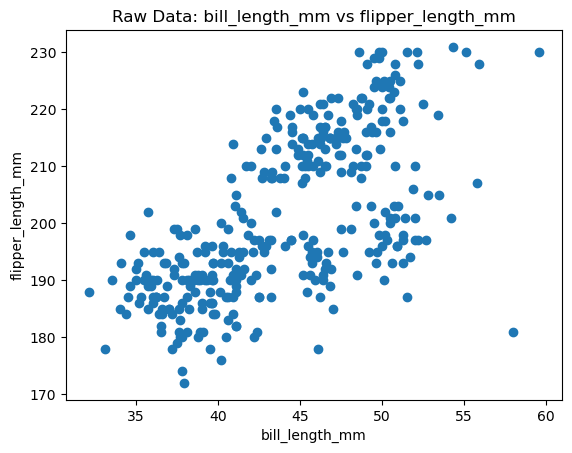

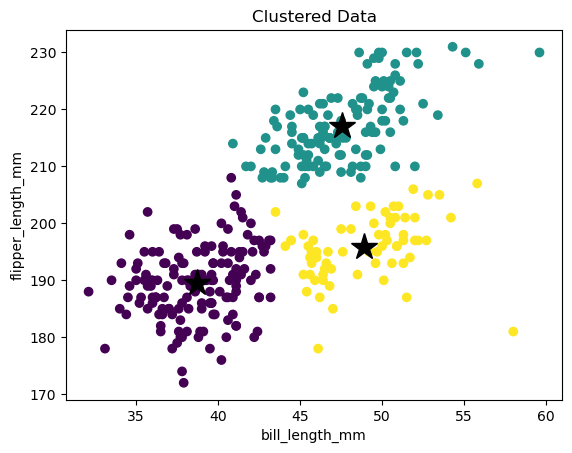

In [45]:
# Raw
plt.scatter(df2['bill_length_mm'], df2['flipper_length_mm'])
plt.xlabel('bill_length_mm')
plt.ylabel('flipper_length_mm')
plt.title('Raw Data: bill_length_mm vs flipper_length_mm')
plt.show()

# Clustered
# Convert the centers from the scaled space back to the original 'mm' space since the data space are also in original space.
# If we dont convert the centers, they will be missaligned 
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(df2['bill_length_mm'], df2['flipper_length_mm'], c=kmeans.labels_)
plt.plot(
    centers[:,0],
    centers[:,1],
    'k*',
    markersize=20
)
plt.xlabel('bill_length_mm')
plt.ylabel('flipper_length_mm')
plt.title('Clustered Data')
plt.show()

Question 5

Why choose this dataset?
- This was chosen because it has a reasonable amount of missing values and more than
  2 numerical features. It also contains the species column which is useful to evaluate our result if the unsupervised model discovered the structure of the data.
  
Why k-means is appropriate?
- Its appropriate because we want to seperate the data into a number of distinct groups which is 3 in our case. The plot above shows that the three penguin species do form subgroups in the given dataset.

Question 6

Expectation:
- I expected that the k-means algorithm would seperate the penguins into three different clusters which represents their species. The Gentoo penguins are the largest among the other two species. So, I expected that species to have one very distinct cluster. I expected an overlap between Adelie and Chinstrap species since they have similar physical characteristics.

Comparing results with expectation:
- My results match my expectations very well. By looking at the plot we can see that the blue cluster is a very distinct cluster which is most likely the Gentoo penguins with long flippers and bill lenght. We can also see the other two clusters which are Adelie and Chinstrap are seperated into two different clusters. There is a slight overlap between them. 